In [1]:
!pip install -q nibabel scipy torch torchvision matplotlib tqdm

import os
import json
import math
from pathlib import Path
from typing import Dict, Any, Tuple, List

import numpy as np
import scipy.ndimage as ndimage
import nibabel as nib
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device đang sử dụng: {device}")

Device đang sử dụng: cuda


In [2]:
class ResBlock3D(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, dropout: float = 0.2):
        super().__init__()
        self.conv1 = nn.Conv3d(in_ch, out_ch, kernel_size=3, padding=1, bias=False)
        self.norm1 = nn.InstanceNorm3d(out_ch, affine=True)
        self.relu = nn.LeakyReLU(negative_slope=0.01, inplace=True)
        self.drop = nn.Dropout3d(dropout)
        self.conv2 = nn.Conv3d(out_ch, out_ch, kernel_size=3, padding=1, bias=False)
        self.norm2 = nn.InstanceNorm3d(out_ch, affine=True)

        if in_ch != out_ch:
            self.skip = nn.Conv3d(in_ch, out_ch, kernel_size=1, bias=False)
        else:
            self.skip = nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = self.skip(x)
        out = self.relu(self.norm1(self.conv1(x)))
        out = self.drop(out)
        out = self.norm2(self.conv2(out))
        out = self.relu(out + residual)
        return out

class ResidualUNet3D(nn.Module):
    def __init__(
        self,
        in_channels: int = 4,
        num_classes: int = 4,
        features: tuple = (16, 32, 64, 128),
        bottleneck: int = 256,
        dropout: float = 0.2
    ):
        super().__init__()
        f1, f2, f3, f4 = features

        self.stem = nn.Conv3d(in_channels, f1, kernel_size=3, padding=1, bias=False)
        self.enc1 = ResBlock3D(f1, f1, dropout)
        self.down1 = nn.MaxPool3d(kernel_size=2, stride=2)

        self.enc2 = ResBlock3D(f1, f2, dropout)
        self.down2 = nn.MaxPool3d(kernel_size=2, stride=2)

        self.enc3 = ResBlock3D(f2, f3, dropout)
        self.down3 = nn.MaxPool3d(kernel_size=2, stride=2)

        self.enc4 = ResBlock3D(f3, f4, dropout)
        self.down4 = nn.MaxPool3d(kernel_size=2, stride=2)

        self.bottleneck = ResBlock3D(f4, bottleneck, dropout)

        self.up4 = nn.ConvTranspose3d(bottleneck, f4, kernel_size=2, stride=2)
        self.dec4 = ResBlock3D(f4 + f4, f4, dropout)

        self.up3 = nn.ConvTranspose3d(f4, f3, kernel_size=2, stride=2)
        self.dec3 = ResBlock3D(f3 + f3, f3, dropout)

        self.up2 = nn.ConvTranspose3d(f3, f2, kernel_size=2, stride=2)
        self.dec2 = ResBlock3D(f2 + f2, f2, dropout)

        self.up1 = nn.ConvTranspose3d(f2, f1, kernel_size=2, stride=2)
        self.dec1 = ResBlock3D(f1 + f1, f1, dropout)

        self.head = nn.Conv3d(f1, num_classes, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem(x)
        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))
        e4 = self.enc4(self.down3(e3))

        b = self.bottleneck(self.down4(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.head(d1)

def enable_mc_dropout(model: nn.Module) -> None:
    model.eval()
    for m in model.modules():
        if isinstance(m, (nn.Dropout, nn.Dropout2d, nn.Dropout3d)):
            m.train()

In [3]:
MODEL_WEIGHTS_PATH = Path("/content/unet3d_final_fp32.pt")
CALIBRATION_CACHE_PATH = Path("/content/calibration_cache.json")
if not CALIBRATION_CACHE_PATH.exists():
    CALIBRATION_CACHE_PATH = Path("/content/calibration_cache")

# 1. Khởi tạo mô hình
model = ResidualUNet3D(
    in_channels=4,
    num_classes=4,
    features=(16, 32, 64, 128),
    bottleneck=256,
    dropout=0.2
).to(device)

# 2. Tải trọng số .pt
if not MODEL_WEIGHTS_PATH.exists():
    alt_path = Path("/content/unet3d_final_fp32.pth")
    if alt_path.exists():
        MODEL_WEIGHTS_PATH = alt_path

if MODEL_WEIGHTS_PATH.exists():
    checkpoint = torch.load(str(MODEL_WEIGHTS_PATH), map_location=device)
    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        model.load_state_dict(checkpoint["model_state_dict"])
    elif isinstance(checkpoint, dict):
        model.load_state_dict(checkpoint)
    print(f"Đã tải thành công trọng số từ: {MODEL_WEIGHTS_PATH}")
else:
    raise FileNotFoundError(f"Không tìm thấy file checkpoint tại: {MODEL_WEIGHTS_PATH}")

enable_mc_dropout(model)

# 3. Đọc hệ số hiệu chuẩn calibration_cache
if CALIBRATION_CACHE_PATH.exists():
    with open(CALIBRATION_CACHE_PATH, "r", encoding="utf-8") as f:
        cache_data = json.load(f)
    calib_factors = cache_data.get("calibration_factors", {})
    a_wt = float(calib_factors.get("a_wt", 1.25))
    a_tc = float(calib_factors.get("a_tc", 1.20))
    a_et = float(calib_factors.get("a_et", 1.15))
    print(f"Đã tải calibration_cache: a_wt={a_wt}, a_tc={a_tc}, a_et={a_et}")
else:
    a_wt, a_tc, a_et = 1.25, 1.20, 1.15
    print(f"Không tìm thấy calibration_cache, sử dụng hệ số mặc định: a_wt={a_wt}, a_tc={a_tc}, a_et={a_et}")

Đã tải thành công trọng số từ: /content/unet3d_final_fp32.pth
Đã tải calibration_cache: a_wt=1.75, a_tc=2.867, a_et=2.6526


In [4]:
def p95_normalize(vol: np.ndarray) -> np.ndarray:
    vol = vol.astype(np.float32, copy=False)
    nz = vol[vol != 0]
    if nz.size == 0:
        return np.zeros_like(vol, dtype=np.float32)
    p95 = np.percentile(nz, 95.0)
    out = np.zeros_like(vol, dtype=np.float32)
    if p95 > 0:
        mask = vol != 0
        out[mask] = vol[mask] / p95
    return out

# Đường dẫn 4 file MRI
t1ce_path = Path("/content/BraTS20_Validation_001_t1ce.nii")
t1_path = Path("/content/BraTS20_Validation_001_t1.nii")
t2_path = Path("/content/BraTS20_Validation_001_t2.nii")
flair_path = Path("/content/BraTS20_Validation_001_flair.nii")

# Đọc file
flair_nii = nib.load(str(flair_path))
t1_nii = nib.load(str(t1_path))
t1ce_nii = nib.load(str(t1ce_path))
t2_nii = nib.load(str(t2_path))

orig_affine = flair_nii.affine.copy()
orig_header = flair_nii.header.copy()

zooms = orig_header.get_zooms()[:3]
voxel_vol_cm3 = float(abs(zooms[0] * zooms[1] * zooms[2])) / 1000.0

flair_data = p95_normalize(flair_nii.get_fdata(dtype=np.float32))
t1_data = p95_normalize(t1_nii.get_fdata(dtype=np.float32))
t1ce_data = p95_normalize(t1ce_nii.get_fdata(dtype=np.float32))
t2_data = p95_normalize(t2_nii.get_fdata(dtype=np.float32))

# Thứ tự kênh chuẩn: [FLAIR, T1, T1ce, T2] và đổi trục (H, W, D) -> (D, H, W)
stacked_image = np.stack([flair_data, t1_data, t1ce_data, t2_data], axis=0).transpose(0, 3, 1, 2)
print(f"Tensor đầu vào (C, D, H, W): {stacked_image.shape} | Thể tích 1 voxel: {voxel_vol_cm3:.6f} cm³")

Tensor đầu vào (C, D, H, W): (4, 155, 240, 240) | Thể tích 1 voxel: 0.001000 cm³


In [5]:
@torch.no_grad()
def predict_mc_dropout_batched(
    model: nn.Module,
    image: np.ndarray,
    patch_size: Tuple[int, int, int] = (128, 128, 128),
    overlap: float = 0.5,
    num_passes: int = 20,
    batch_t: int = 2
) -> Dict[str, np.ndarray]:
    c, orig_d, orig_h, orig_w = image.shape
    pd, ph, pw = patch_size

    # Tự động zero-padding nếu chiều bất kỳ nhỏ hơn patch_size (chống lỗi lệch shape)
    pad_d = max(0, pd - orig_d)
    pad_h = max(0, ph - orig_h)
    pad_w = max(0, pw - orig_w)

    if pad_d > 0 or pad_h > 0 or pad_w > 0:
        image = np.pad(
            image,
            ((0, 0), (0, pad_d), (0, pad_h), (0, pad_w)),
            mode="constant",
            constant_values=0
        )

    _, d, h, w = image.shape

    step_d = max(1, int(pd * (1 - overlap)))
    step_h = max(1, int(ph * (1 - overlap)))
    step_w = max(1, int(pw * (1 - overlap)))

    steps_d = list(range(0, max(1, d - pd + 1), step_d))
    if steps_d[-1] + pd < d: steps_d.append(d - pd)

    steps_h = list(range(0, max(1, h - ph + 1), step_h))
    if steps_h[-1] + ph < h: steps_h.append(h - ph)

    steps_w = list(range(0, max(1, w - pw + 1), step_w))
    if steps_w[-1] + pw < w: steps_w.append(w - pw)

    prob_wt_list, prob_tc_list, prob_et_list = [], [], []
    is_cuda = (device.type == "cuda")
    enable_mc_dropout(model)

    print(f"Bắt đầu chạy {num_passes} lượt MC Dropout (ghép batch {batch_t} trên GPU)...")
    for t_step in tqdm(range(0, num_passes, batch_t), desc="Inference MC Dropout"):
        cur_b = min(batch_t, num_passes - t_step)
        prob_accum = np.zeros((cur_b, 4, d, h, w), dtype=np.float32)
        count_accum = np.zeros((d, h, w), dtype=np.float32)

        for sd in steps_d:
            for sh in steps_h:
                for sw in steps_w:
                    sub_vol = image[:, sd:sd + pd, sh:sh + ph, sw:sw + pw]
                    tensor = torch.from_numpy(sub_vol.astype(np.float32)).unsqueeze(0).repeat(cur_b, 1, 1, 1, 1).to(device)

                    if is_cuda:
                        with torch.amp.autocast("cuda", dtype=torch.float16):
                            logits = model(tensor)
                    else:
                        logits = model(tensor)

                    probs = torch.softmax(logits, dim=1).cpu().numpy()
                    prob_accum[:, :, sd:sd + pd, sh:sh + ph, sw:sw + pw] += probs
                    count_accum[sd:sd + pd, sh:sh + ph, sw:sw + pw] += 1.0

        count_accum = np.maximum(count_accum, 1.0)
        prob_accum /= count_accum[None, None, ...]

        # Cắt bỏ phần padding thừa trả về đúng kích thước gốc
        prob_accum = prob_accum[:, :, :orig_d, :orig_h, :orig_w]

        for b in range(cur_b):
            p_et = prob_accum[b, 1]
            p_tc = prob_accum[b, 1] + prob_accum[b, 2]
            p_wt = prob_accum[b, 1] + prob_accum[b, 2] + prob_accum[b, 3]

            prob_wt_list.append(p_wt.astype(np.float16))
            prob_tc_list.append(p_tc.astype(np.float16))
            prob_et_list.append(p_et.astype(np.float16))

    return {
        "WT": np.stack(prob_wt_list, axis=0),
        "TC": np.stack(prob_tc_list, axis=0),
        "ET": np.stack(prob_et_list, axis=0)
    }

mc_probs = predict_mc_dropout_batched(model, stacked_image, patch_size=(128, 128, 128), overlap=0.5, num_passes=20, batch_t=2)

def compute_calibrated_quantiles(
    prob_arr: np.ndarray,
    voxel_vol_cm3: float,
    a_scale: float
) -> Tuple[List[float], Tuple[float, float], np.ndarray, np.ndarray, np.ndarray]:
    t_prob = torch.from_numpy(prob_arr.astype(np.float32)).to(device)
    d, h, w = prob_arr.shape[1], prob_arr.shape[2], prob_arr.shape[3]

    valid_mask = (t_prob.max(dim=0).values > 0.01)
    q_levels = torch.linspace(0.01, 0.99, 99, device=device)

    empty_mask = np.zeros((d, h, w), dtype=bool)
    if not valid_mask.any():
        return [0.0] * 99, (0.0, 0.0), empty_mask, empty_mask, empty_mask

    valid_voxels = t_prob[:, valid_mask]
    q_voxels = torch.quantile(valid_voxels, q_levels, dim=0)

    # Soft Volumetry theo Eaton-Rosen
    vol_cdf = q_voxels.sum(dim=1).cpu().numpy().astype(np.float64) * voxel_vol_cm3
    vol_cdf_rounded = [round(float(v), 2) for v in vol_cdf]

    v_med = vol_cdf[49]
    v_low_raw = vol_cdf[2]
    v_high_raw = vol_cdf[96]

    # Khoảng tin cậy 95% có hiệu chuẩn
    raw_half_width = max((v_high_raw - v_low_raw) / 2.0, 0.05 * v_med + 0.2)
    ci_low = max(0.0, round(float(v_med - a_scale * raw_half_width), 2))
    ci_high = round(float(v_med + a_scale * raw_half_width), 2)

    # Ngưỡng hóa mặt nạ không gian
    m50_valid = (q_voxels[49] >= 0.5).cpu().numpy()
    th_low = min(0.85, 0.5 + 0.15 * min(a_scale, 3.0))
    th_high = max(0.15, 0.5 - 0.15 * min(a_scale, 3.0))

    m05_valid = (q_voxels[4] >= th_low).cpu().numpy()
    m95_valid = (q_voxels[94] >= th_high).cpu().numpy()

    valid_mask_np = valid_mask.cpu().numpy()
    mask_05 = np.zeros((d, h, w), dtype=bool)
    mask_50 = np.zeros((d, h, w), dtype=bool)
    mask_95 = np.zeros((d, h, w), dtype=bool)

    mask_05[valid_mask_np] = m05_valid
    mask_50[valid_mask_np] = m50_valid
    mask_95[valid_mask_np] = m95_valid

    del t_prob, valid_voxels, q_voxels
    if device.type == "cuda":
        torch.cuda.empty_cache()

    return vol_cdf_rounded, (ci_low, ci_high), mask_05, mask_50, mask_95

def postprocess_volume(pred: np.ndarray, second_lcc_min: int = 100, et_min: int = 50) -> np.ndarray:
    output = pred.copy()
    tumor = output > 0
    labeled, count = ndimage.label(tumor)

    if count > 0:
        sizes = ndimage.sum(tumor, labeled, index=np.arange(1, count + 1))
        order = np.argsort(sizes)[::-1]
        keep_ids = [int(order[0] + 1)]

        if len(order) >= 2 and sizes[order[1]] >= second_lcc_min:
            keep_ids.append(int(order[1] + 1))

        keep_mask = np.isin(labeled, keep_ids)
        output[~keep_mask] = 0

    et_count = int((output == 1).sum())
    if 0 < et_count < et_min:
        output[output == 1] = 2

    return output

# Tính toán phân vị
wt_cdf, wt_ci95, wt_05, wt_50, wt_95 = compute_calibrated_quantiles(mc_probs["WT"], voxel_vol_cm3, a_wt)
tc_cdf, tc_ci95, tc_05, tc_50, tc_95 = compute_calibrated_quantiles(mc_probs["TC"], voxel_vol_cm3, a_tc)
et_cdf, et_ci95, et_05, et_50, et_95 = compute_calibrated_quantiles(mc_probs["ET"], voxel_vol_cm3, a_et)

# Ghép mặt nạ đa nhãn chuẩn BraTS (1: ET, 2: NCR, 3: ED)
d, h, w = stacked_image.shape[1], stacked_image.shape[2], stacked_image.shape[3]
def create_multilabel_mask(wt_m, tc_m, et_m):
    m = np.zeros((d, h, w), dtype=np.uint8)
    m[wt_m] = 3
    m[tc_m] = 2
    m[et_m] = 1
    return postprocess_volume(m, second_lcc_min=100, et_min=50)

mask_p05 = create_multilabel_mask(wt_05, tc_05, et_05)
mask_p50 = create_multilabel_mask(wt_50, tc_50, et_50)
mask_p95 = create_multilabel_mask(wt_95, tc_95, et_95)

# Lưu 3 file NIfTI
out_p05_path = "/content/BraTS20_Validation_001_seg_p05.nii.gz"
out_p50_path = "/content/BraTS20_Validation_001_seg_p50.nii.gz"
out_p95_path = "/content/BraTS20_Validation_001_seg_p95.nii.gz"

for m_arr, p_path in [(mask_p05, out_p05_path), (mask_p50, out_p50_path), (mask_p95, out_p95_path)]:
    spatial = m_arr.transpose(1, 2, 0).astype(np.uint8)
    nii_obj = nib.Nifti1Image(spatial, orig_affine, orig_header)
    nib.save(nii_obj, p_path)

print(f"Đã lưu thành công 3 mặt nạ phân vị:\n - {out_p05_path}\n - {out_p50_path}\n - {out_p95_path}")

Bắt đầu chạy 20 lượt MC Dropout (ghép batch 2 trên GPU)...


Inference MC Dropout:   0%|          | 0/10 [00:00<?, ?it/s]

Đã lưu thành công 3 mặt nạ phân vị:
 - /content/BraTS20_Validation_001_seg_p05.nii.gz
 - /content/BraTS20_Validation_001_seg_p50.nii.gz
 - /content/BraTS20_Validation_001_seg_p95.nii.gz


BÁO CÁO THỂ TÍCH KHỐI U CÓ HIỆU CHUẨN (CALIBRATED UQ REPORT):
Whole Tumor (WT) : Trung vị = 132.03 cm³ | 95% CI: [120.13, 143.93] cm³
Tumor Core (TC)  : Trung vị =  23.12 cm³ | 95% CI: [18.38, 27.86] cm³
Enhancing (ET)   : Trung vị =  21.17 cm³ | 95% CI: [17.83, 24.50] cm³


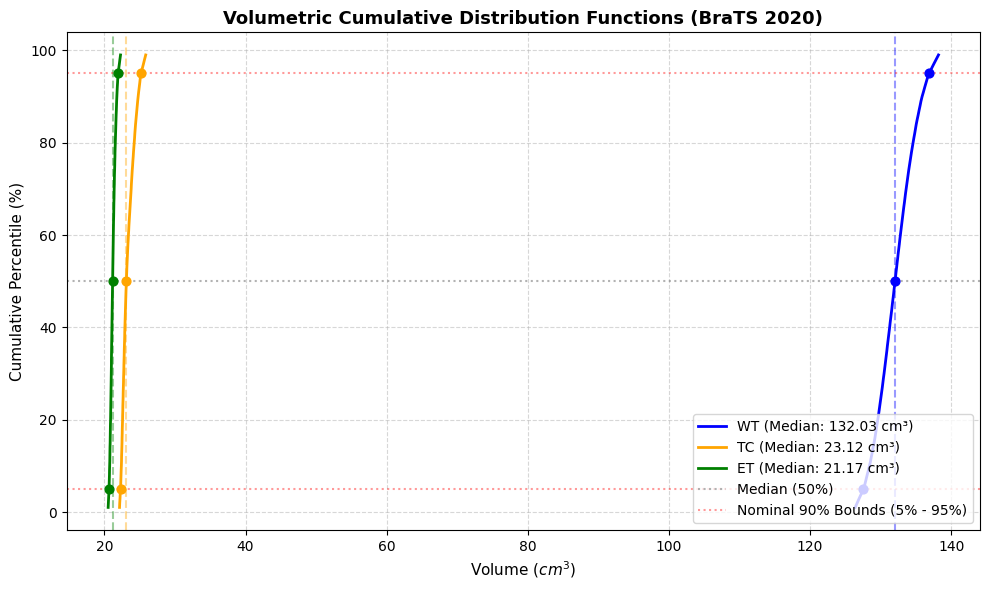

In [6]:
# 1. Bảng số liệu tóm tắt
print("=" * 65)
print("BÁO CÁO THỂ TÍCH KHỐI U CÓ HIỆU CHUẨN (CALIBRATED UQ REPORT):")
print("=" * 65)
print(f"Whole Tumor (WT) : Trung vị = {wt_cdf[49]:>6.2f} cm³ | 95% CI: [{wt_ci95[0]:>5.2f}, {wt_ci95[1]:>5.2f}] cm³")
print(f"Tumor Core (TC)  : Trung vị = {tc_cdf[49]:>6.2f} cm³ | 95% CI: [{tc_ci95[0]:>5.2f}, {tc_ci95[1]:>5.2f}] cm³")
print(f"Enhancing (ET)   : Trung vị = {et_cdf[49]:>6.2f} cm³ | 95% CI: [{et_ci95[0]:>5.2f}, {et_ci95[1]:>5.2f}] cm³")
print("=" * 65)

# 2. Vẽ biểu đồ Volumetric CDF Curve
percentiles = np.linspace(1, 99, 99)
plt.figure(figsize=(10, 6), dpi=100)

plt.plot(wt_cdf, percentiles, label=f"WT (Median: {wt_cdf[49]} cm³)", color="blue", lw=2)
plt.plot(tc_cdf, percentiles, label=f"TC (Median: {tc_cdf[49]} cm³)", color="orange", lw=2)
plt.plot(et_cdf, percentiles, label=f"ET (Median: {et_cdf[49]} cm³)", color="green", lw=2)

# Đánh dấu các mốc tin cậy
for cdf, color in [(wt_cdf, "blue"), (tc_cdf, "orange"), (et_cdf, "green")]:
    plt.axvline(cdf[49], color=color, linestyle="--", alpha=0.4)
    plt.scatter([cdf[4], cdf[49], cdf[94]], [5, 50, 95], color=color, s=40, zorder=5)

plt.axhline(50, color="gray", linestyle=":", alpha=0.6, label="Median (50%)")
plt.axhline(5, color="red", linestyle=":", alpha=0.4, label="Nominal 90% Bounds (5% - 95%)")
plt.axhline(95, color="red", linestyle=":", alpha=0.4)

plt.title("Volumetric Cumulative Distribution Functions (BraTS 2020)", fontsize=13, fontweight="bold")
plt.xlabel("Volume ($cm^3$)", fontsize=11)
plt.ylabel("Cumulative Percentile (%)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()